<a href="https://colab.research.google.com/github/iffat124320012-cpu/heart-sound-pcg-classification/blob/main/heart_sound_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import wavfile

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# -------------------------------------------------------------
# 1. GENERATOR SINYAL AUDIO JANTUNG SINTETIK (TEKNIK FISIKA)
# -------------------------------------------------------------
output_dir = "./synthetic_heart_sounds"
os.makedirs(output_dir, exist_ok=True)

sr = 22050  # Sampling rate 22.050 Hz
duration = 1.5  # Durasi sinyal 1.5 detik
t = np.linspace(0, duration, int(sr * duration), endpoint=False)

def generate_pcg_signal(is_abnormal=False):
    # Komponen S1 (Lub) dan S2 (Dub) berbasis sinyal sinusoidal fisis
    s1 = np.sin(2 * np.pi * 50 * t) * np.exp(-((t - 0.3)**2) / 0.005)
    s2 = np.sin(2 * np.pi * 70 * t) * np.exp(-((t - 0.7)**2) / 0.005)
    clean_signal = s1 + s2

    if is_abnormal:
        # Turbulensi frekuensi tinggi (Murmur) pada sinyal abnormal
        murmur = 0.4 * np.random.normal(0, 1, len(t)) * np.exp(-((t - 0.5)**2) / 0.08)
        signal = clean_signal + murmur
    else:
        # Noise latar belakang ringan
        noise = 0.05 * np.random.normal(0, 1, len(t))
        signal = clean_signal + noise

    # Normalisasi amplitudo
    signal = signal / np.max(np.abs(signal))
    return signal

print("Membuat 100 sampel sinyal audio jantung fisis...")
audio_files = []
labels_dict = {}

for i in range(50):
    # 50 sampel Normal
    sig_norm = generate_pcg_signal(is_abnormal=False)
    path_norm = os.path.join(output_dir, f"normal_{i}.wav")
    wavfile.write(path_norm, sr, (sig_norm * 32767).astype(np.int16))
    audio_files.append(path_norm)
    labels_dict[path_norm] = "Normal"

    # 50 sampel Abnormal (Murmur)
    sig_abnorm = generate_pcg_signal(is_abnormal=True)
    path_abnorm = os.path.join(output_dir, f"abnormal_{i}.wav")
    wavfile.write(path_abnorm, sr, (sig_abnorm * 32767).astype(np.int16))
    audio_files.append(path_abnorm)
    labels_dict[path_abnorm] = "Abnormal"

print("Sinyal audio berhasil dibangkitkan!")

# -------------------------------------------------------------
# 2. FUNGSI EKSTRAKSI FITUR (DIGITAL SIGNAL PROCESSING)
# -------------------------------------------------------------
def extract_audio_features(file_path):
    try:
        audio, sample_rate = librosa.load(file_path, sr=22050)

        # 1. Ekstraksi 40 koefisien MFCC
        mfccs = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
        mfccs_scaled = np.mean(mfccs.T, axis=0)

        # 2. Ekstraksi Spectral Centroid
        spectral_centroids = librosa.feature.spectral_centroid(y=audio, sr=sample_rate)
        spectral_centroid_scaled = np.mean(spectral_centroids)

        # Gabungkan vektor fitur
        features = np.append(mfccs_scaled, spectral_centroid_scaled)
        return features
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

# -------------------------------------------------------------
# 3. PROSES EKSTRAKSI FITUR UNTUK ENTIRE DATASET
# -------------------------------------------------------------
features_list = []
labels = []

print("\nMengekstrak fitur MFCC & Spectral Centroid...")
for file_path in audio_files:
    feat = extract_audio_features(file_path)
    if feat is not None:
        features_list.append(feat)
        labels.append(labels_dict[file_path])

X = np.array(features_list)
y = np.array(labels)

print(f"Ekstraksi Selesai! Berhasil memproses {len(X)} sampel audio.")
print(f"Distribusi Kelas -> Normal: {list(y).count('Normal')}, Abnormal: {list(y).count('Abnormal')}")

# -------------------------------------------------------------
# 4. TRAINING & EVALUASI MODEL MACHINE LEARNING
# -------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print("\n" + "="*40)
print(f"Akurasi Model Biomedis: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("="*40)
print("\nLaporan Klasifikasi:\n", classification_report(y_test, y_pred))

Membuat 100 sampel sinyal audio jantung fisis...
Sinyal audio berhasil dibangkitkan!

Mengekstrak fitur MFCC & Spectral Centroid...
Ekstraksi Selesai! Berhasil memproses 100 sampel audio.
Distribusi Kelas -> Normal: 50, Abnormal: 50

Akurasi Model Biomedis: 100.00%

Laporan Klasifikasi:
               precision    recall  f1-score   support

    Abnormal       1.00      1.00      1.00        10
      Normal       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



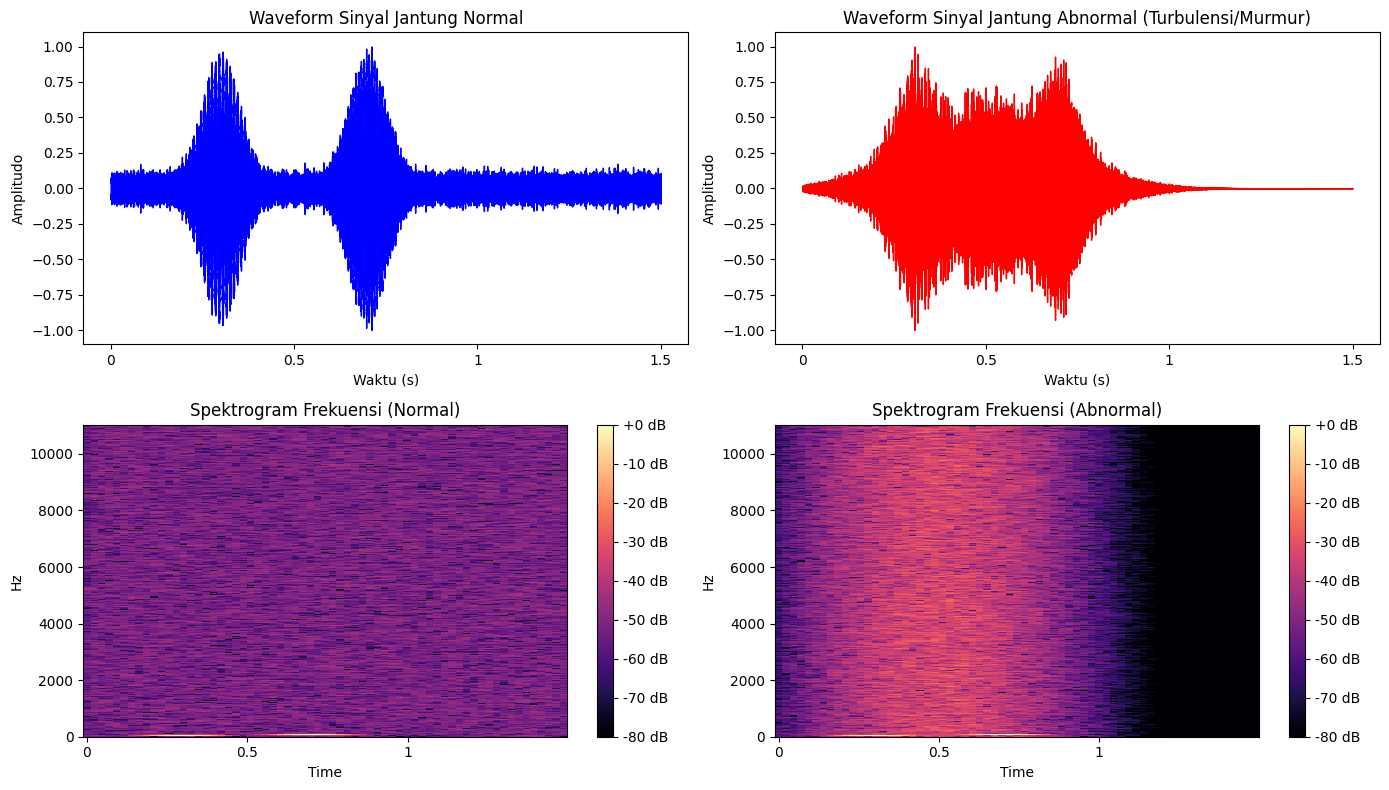

In [ ]:
import matplotlib.pyplot as plt
import librosa.display

# Ambil 1 sampel Normal dan 1 sampel Abnormal
sample_norm = [f for f in audio_files if "normal" in f][0]
sample_abnorm = [f for f in audio_files if "abnormal" in f][0]

y_norm, sr = librosa.load(sample_norm, sr=22050)
y_abnorm, _ = librosa.load(sample_abnorm, sr=22050)

plt.figure(figsize=(14, 8))

# 1. Waveform Normal vs Abnormal
plt.subplot(2, 2, 1)
librosa.display.waveshow(y_norm, sr=sr, color='blue')
plt.title('Waveform Sinyal Jantung Normal')
plt.xlabel('Waktu (s)')
plt.ylabel('Amplitudo')

plt.subplot(2, 2, 2)
librosa.display.waveshow(y_abnorm, sr=sr, color='red')
plt.title('Waveform Sinyal Jantung Abnormal (Turbulensi/Murmur)')
plt.xlabel('Waktu (s)')
plt.ylabel('Amplitudo')

# 2. Spektrogram STFT Normal vs Abnormal
plt.subplot(2, 2, 3)
D_norm = librosa.amplitude_to_db(np.abs(librosa.stft(y_norm)), ref=np.max)
librosa.display.specshow(D_norm, sr=sr, x_axis='time', y_axis='hz', cmap='magma')
plt.colorbar(format='%+2.0f dB')
plt.title('Spektrogram Frekuensi (Normal)')

plt.subplot(2, 2, 4)
D_abnorm = librosa.amplitude_to_db(np.abs(librosa.stft(y_abnorm)), ref=np.max)
librosa.display.specshow(D_abnorm, sr=sr, x_axis='time', y_axis='hz', cmap='magma')
plt.colorbar(format='%+2.0f dB')
plt.title('Spektrogram Frekuensi (Abnormal)')

plt.tight_layout()
plt.show()

In [ ]:
import joblib

# Simpan model
joblib.dump(clf, "heart_sound_model.pkl")
print("Model berhasil disimpan sebagai 'heart_sound_model.pkl'!")

Model berhasil disimpan sebagai 'heart_sound_model.pkl'!
